# Ballon d'Or 2026 — EDA, preparation and modelling

Companion to `ballon_dor_2026_modelling_spec.md`. This notebook grows step by step.

## A. Load and describe
Goal of this step: load both snapshots and see what we have — shape, size, data types and how much data is there. No cleaning, no features, no modelling yet.

In [1]:
import hashlib
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

SEED = 7
T1_PATH = Path("player_snapshot_t1.csv")
T2_PATH = Path("player_snapshot_t2.csv")
TARGET_COLS = ["bdo_points", "bdo_rank", "vote_share"]
FORECAST_EDITION = 2026

np.random.seed(SEED)
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()

commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
print("git commit :", commit)
print("pandas     :", pd.__version__, "| numpy:", np.__version__)
for p in (T1_PATH, T2_PATH):
    print(f"{p.name:26s} sha256={sha256(p)[:16]}...")

git commit : 901798d
pandas     : 3.0.6 | numpy: 2.5.4
player_snapshot_t1.csv     sha256=249bb1ac9a623070...
player_snapshot_t2.csv     sha256=f9af1fd20747536e...


In [2]:
t1 = pd.read_csv(T1_PATH)
t2 = pd.read_csv(T2_PATH)
print("Loaded.")

Loaded.


### A1. Shape and size

In [3]:
size = pd.DataFrame({
    "rows": [len(t1), len(t2)],
    "columns": [t1.shape[1], t2.shape[1]],
    "cells": [t1.size, t2.size],
    "file_size_kb": [T1_PATH.stat().st_size / 1024, T2_PATH.stat().st_size / 1024],
    "memory_kb": [t1.memory_usage(deep=True).sum() / 1024, t2.memory_usage(deep=True).sum() / 1024],
}, index=["T1", "T2"]).round(1)
display(size)

extra = [c for c in t2.columns if c not in t1.columns]
missing_from_t2 = [c for c in t1.columns if c not in t2.columns]
print(f"T2 has {len(extra)} extra columns (post-window block); T1 columns missing from T2: {missing_from_t2}")
print(extra)

,rows,columns,cells,file_size_kb,memory_kb
T1,150,91,13650,102.3,186.9
T2,150,111,16650,130.3,208.3


T2 has 20 extra columns (post-window block); T1 columns missing from T2: []
['wiki_views_post', 'wiki_views_post_juror_w', 'wiki_views_final14', 'wiki_views_final14_juror_w', 'news_vol_post', 'news_vol_post_juror_w', 'news_coverage_ratio_post', 'news_tone_post', 'news_headlines_scored_post', 'post_minutes', 'post_apps', 'post_goal_contribs', 'post_npxg_xa_p90', 'post_npxg_xa_p90_opp_adj', 'post_avg_rating', 'post_big_game_rating', 'post_ucl_goal_contribs', 'post_intl_goal_contribs', 'post_transfer', 'post_injury']


### A2. Data types

In [4]:
def dtype_group(s: pd.Series) -> str:
    if pd.api.types.is_bool_dtype(s):
        return "bool"
    if pd.api.types.is_integer_dtype(s):
        return "integer"
    if pd.api.types.is_float_dtype(s):
        return "float"
    return "text/object"

counts = pd.DataFrame({
    "T1": t1.apply(dtype_group).value_counts(),
    "T2": t2.apply(dtype_group).value_counts(),
}).fillna(0).astype(int)
display(counts)

,T1,T2
bool,13,15
float,30,40
integer,34,42
text/object,14,14


In [5]:
BLOCKS = {
    "identity": ["edition", "snapshot", "snapshot_date", "player_key", "player_name", "nationality", "position_group",
                 "age_at_window_end", "is_goalkeeper", "club_key", "club_team_id", "league_key", "built_at", "pipeline_version"],
    "targets": TARGET_COLS,
    "history": ["prev_bdo_rank", "career_bdo_podiums_before", "is_defending_winner", "consecutive_podiums"],
    "club_performance": [c for c in t1.columns if c.startswith(("club_minutes", "club_apps", "club_goals", "club_assists",
                         "club_np", "club_xa", "club_xg", "club_avg", "big_game", "ucl_minutes", "ucl_goal", "ucl_ko"))],
    "international": [c for c in t1.columns if c.startswith(("intl_", "tourn_", "finals_", "final_", "scored_winner"))],
    "honors": ["won_ucl", "won_league", "won_domestic_cup", "won_world_cup", "won_continental", "won_other_uefa",
               "ucl_back_to_back", "league_poty", "club_trophies_n"],
    "team_context": ["league_finish", "league_n_teams", "league_finish_partial", "ucl_stage_reached", "club_rating_window_end",
                     "club_rating_rank_window_end", "club_rating_fallback", "uefa_country_coeff_rank", "league_mean_rating",
                     "nt_fifa_rank_window_end", "nt_elo_window_end", "nt_tourn_stage_reached"],
    "attention": [c for c in t1.columns if c.startswith(("wiki_", "news_"))],
    "voter_context": ["jurors_same_nation", "jurors_same_confed", "jurors_league_country", "teammates_on_shortlist",
                      "nat_teammates_on_shortlist"],
    "post_window_T2_only": extra,
}
assigned = [c for cols in BLOCKS.values() for c in cols]
unassigned = [c for c in t2.columns if c not in assigned]
dupes = pd.Series(assigned).loc[lambda s: s.duplicated()].tolist()
print("unassigned columns:", unassigned)
print("columns in more than one block:", dupes)

unassigned columns: []
columns in more than one block: []


In [6]:
block_of = {c: b for b, cols in BLOCKS.items() for c in cols[::-1]}
profile = pd.DataFrame({
    "block": pd.Series(block_of),
    "dtype": t2.dtypes.astype(str),
    "non_null": t2.notna().sum(),
    "null": t2.isna().sum(),
    "null_%": (t2.isna().mean() * 100).round(1),
    "n_unique": t2.nunique(),
}).loc[t2.columns]
profile.insert(0, "in_T1", [c in t1.columns for c in profile.index])
display(profile)

,in_T1,block,dtype,non_null,null,null_%,n_unique
edition,True,identity,int64,150,0,0.0,5
snapshot,True,identity,str,150,0,0.0,1
snapshot_date,True,identity,str,150,0,0.0,5
player_key,True,identity,str,150,0,0.0,91
player_name,True,identity,str,150,0,0.0,91
nationality,True,identity,str,150,0,0.0,33
position_group,True,identity,str,150,0,0.0,4
age_at_window_end,True,identity,float64,150,0,0.0,97
is_goalkeeper,True,identity,bool,150,0,0.0,2
bdo_points,True,targets,float64,120,30,20.0,71


### A3. How much data is there?

In [7]:
per_edition = pd.concat({"T1": t1, "T2": t2}).reset_index(level=0).rename(columns={"level_0": "table"})
rows = per_edition.groupby(["edition", "table"]).size().unstack()
rows["role"] = np.where(rows.index == FORECAST_EDITION, "forecast (targets null)", "train / back-test")
display(rows)

uniq = pd.Series({
    "player-season rows": len(t1),
    "distinct players": t1["player_key"].nunique(),
    "distinct clubs": t1["club_key"].nunique(),
    "distinct nationalities": t1["nationality"].nunique(),
    "distinct leagues": t1["league_key"].nunique(),
})
display(uniq.to_frame("count"))

appearances = t1.groupby("player_key").size()
print("Nominations per player (how many players appear in 1, 2, ... 5 editions):")
display(appearances.value_counts().sort_index().rename_axis("editions_nominated").to_frame("players"))

table,T1,T2,role
edition,,,
2022,30,30,train / back-test
2023,30,30,train / back-test
2024,30,30,train / back-test
2025,30,30,train / back-test
2026,30,30,forecast (targets null)


,count
player-season rows,150
distinct players,91
distinct clubs,31
distinct nationalities,33
distinct leagues,9


Nominations per player (how many players appear in 1, 2, ... 5 editions):


,players
editions_nominated,
1,55
2,23
3,7
4,2
5,4


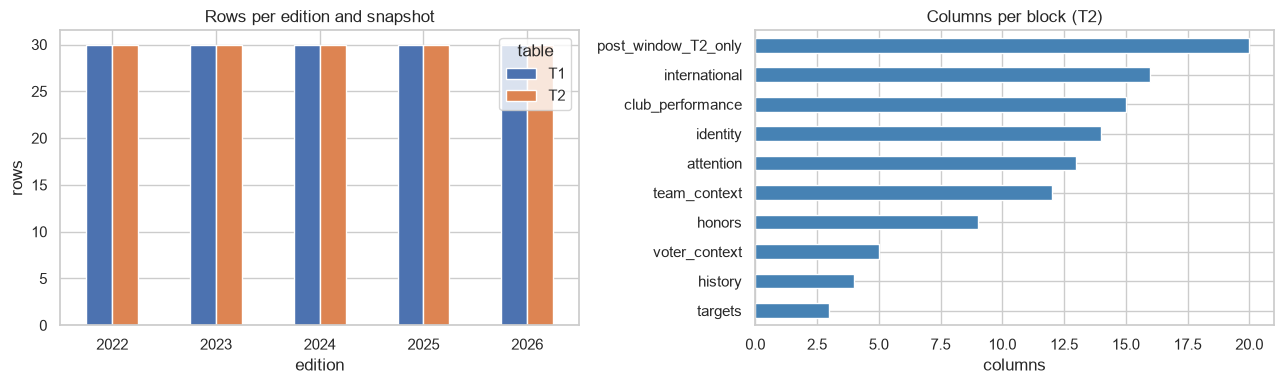

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rows[["T1", "T2"]].plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Rows per edition and snapshot")
axes[0].set_ylabel("rows")
block_sizes = pd.Series({b: len([c for c in cols if c in t2.columns]) for b, cols in BLOCKS.items()}).sort_values()
block_sizes.plot.barh(ax=axes[1], color="steelblue")
axes[1].set_title("Columns per block (T2)")
axes[1].set_xlabel("columns")
plt.tight_layout()
Path("figures/eda").mkdir(parents=True, exist_ok=True)
plt.savefig("figures/eda/a_size_overview.png", dpi=150)
plt.show()

### A4. First look

In [9]:
display(t1.head(8).T.head(45))

,0,1,2,3,4,5,6,7
edition,2022,2022,2022,2022,2022,2022,2022,2022
snapshot,T1,T1,T1,T1,T1,T1,T1,T1
snapshot_date,2022-07-31,2022-07-31,2022-07-31,2022-07-31,2022-07-31,2022-07-31,2022-07-31,2022-07-31
player_key,p_q11571,p_q133903,p_q1354960,p_q13865408,p_q151269,p_q15521306,p_q17274709,p_q1912
player_name,Cristiano Ronaldo,Virgil van Dijk,Mohamed Salah,Joshua Kimmich,Robert Lewandowski,Bernardo Silva,Mike Maignan,Karim Benzema
nationality,Portugal,Netherlands,Egypt,Germany,Poland,Portugal,France,France
position_group,FWD,DEF,FWD,MID,FWD,MID,GK,FWD
age_at_window_end,37.5,31.1,30.1,27.5,33.9,28.0,27.1,34.6
is_goalkeeper,False,False,False,False,False,False,True,False
bdo_points,0.0,1.0,116.0,0.0,170.0,0.0,0.0,549.0


In [10]:
cats = ["position_group", "ucl_stage_reached", "nt_tourn_stage_reached", "tourn_individual_award", "tourn_name", "league_key"]
for c in cats:
    print(f"--- {c}")
    print(t1[c].value_counts(dropna=False).to_string())
    print()

--- position_group
position_group
FWD    70
MID    47
DEF    26
GK      7

--- ucl_stage_reached
ucl_stage_reached
winner          35
QF              29
R16             21
SF              21
NaN             19
final           15
league_phase     7
playoff          3

--- nt_tourn_stage_reached
nt_tourn_stage_reached
NaN       67
winner    18
QF        15
SF        15
R16       14
final     12
group      7
R32        2

--- tourn_individual_award
tourn_individual_award
NaN                            128
Player of the Tournament        11
Best young player                6
Golden Boot winner (Europe)      5

--- tourn_name
tourn_name
NaN                      67
World Cup                52
EURO                     22
Africa Cup of Nations     5
Copa America              4

--- league_key
league_key
47     49
87     33
53     23
54     22
55     16
61      3
536     2
57      1
130     1



In [11]:
key_numeric = ["age_at_window_end", "club_minutes", "club_npxg_xa_p90_opp_adj", "club_avg_rating", "intl_minutes",
               "club_rating_window_end", "wiki_views_in", "news_vol_in", "bdo_points", "vote_share"]
display(t1[key_numeric].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
age_at_window_end,150.0,27.30,4.41,17.10,24.10,27.00,30.18,39.10
club_minutes,150.0,3700.02,634.89,1713.00,3243.50,3805.50,4152.75,5015.00
club_npxg_xa_p90_opp_adj,150.0,0.43,0.28,-0.13,0.20,0.45,0.65,1.08
club_avg_rating,150.0,7.63,0.33,6.52,7.45,7.64,7.85,8.45
intl_minutes,150.0,639.80,283.70,0.00,452.25,625.00,817.00,1440.00
club_rating_window_end,148.0,1948.09,101.76,1639.00,1886.00,1963.50,2026.00,2111.00
wiki_views_in,150.0,6179451.23,8449058.89,960376.00,2297207.25,3529510.50,6296706.50,67307175.00
news_vol_in,150.0,10930.54,11715.03,1167.39,3548.18,7184.54,14120.90,79168.22
bdo_points,120.0,135.78,262.15,0.00,3.75,20.00,117.75,1380.00
vote_share,120.0,0.03,0.06,0.00,0.00,0.01,0.03,0.37


### A5. Quick sanity checks (printed only, nothing is modified)

In [12]:
print("(edition, player_key) unique in T1:", not t1.duplicated(["edition", "player_key"]).any())
print("(edition, player_key) unique in T2:", not t2.duplicated(["edition", "player_key"]).any())
shared = t1.columns
print("T1 in-window columns identical in T2:",
      t1.reset_index(drop=True).equals(t2[shared].reset_index(drop=True)) or
      t1.sort_values(["edition", "player_key"]).reset_index(drop=True).drop(columns=["snapshot", "snapshot_date"]).equals(
          t2.sort_values(["edition", "player_key"]).reset_index(drop=True)[shared].drop(columns=["snapshot", "snapshot_date"])))
print("2026 target columns entirely null:", bool(t1.loc[t1.edition == FORECAST_EDITION, TARGET_COLS].isna().all().all()))
print("2022-25 target columns have no nulls:", bool(t1.loc[t1.edition < FORECAST_EDITION, TARGET_COLS].notna().all().all()))

(edition, player_key) unique in T1: True
(edition, player_key) unique in T2: True
T1 in-window columns identical in T2: True
2026 target columns entirely null: True
2022-25 target columns have no nulls: True


## B. Spec section 2 — edition facts, data quirks and missingness

Everything here is checked against the claims in section 2 of the modelling spec. Checks are printed as `observed` vs `spec` so any mismatch is visible; nothing is modified.

### B1. Edition facts (window end, post-window days, ballot scheme, point totals)

In [13]:
EDITION_FACTS = pd.DataFrame({
    "window_end": pd.to_datetime(["2022-07-31", "2023-07-31", "2024-07-31", "2025-07-13", "2026-07-19"]),
    "spec_t2_date": pd.to_datetime(["2022-09-16", "2023-09-29", "2024-09-27", "2025-08-22", "2026-09-25"]),
    "spec_post_days": [47, 60, 58, 40, 68],
    "ballot_size": [5, 5, 10, 10, 10],
    "points_per_ballot": [16, 16, 67, 67, 67],
    "jurors": [93, 92, 99, 100, 100],
}, index=pd.Index([2022, 2023, 2024, 2025, 2026], name="edition"))

obs = t2.groupby("edition").agg(snapshot_date=("snapshot_date", "first"), n_snapshot_dates=("snapshot_date", "nunique"))
obs["snapshot_date"] = pd.to_datetime(obs["snapshot_date"])
facts = EDITION_FACTS.join(obs)
facts["observed_post_days"] = (facts["snapshot_date"] - facts["window_end"]).dt.days
facts["t2_date_matches"] = facts["snapshot_date"] == facts["spec_t2_date"]
facts["post_days_match"] = facts["observed_post_days"] == facts["spec_post_days"]
facts["observed_points_total"] = t1.groupby("edition")["bdo_points"].sum()
facts["expected_points_total"] = facts["jurors"] * facts["points_per_ballot"]
facts["points_match"] = facts["observed_points_total"] == facts["expected_points_total"]
display(facts[["window_end", "snapshot_date", "observed_post_days", "spec_post_days", "t2_date_matches", "post_days_match",
               "ballot_size", "jurors", "observed_points_total", "expected_points_total", "points_match"]])

t1_dates = t1.groupby("edition")["snapshot_date"].agg(["first", "nunique"])
print("T1 snapshot dates (should equal window end):")
display(t1_dates)

,window_end,snapshot_date,observed_post_days,spec_post_days,t2_date_matches,post_days_match,ballot_size,jurors,observed_points_total,expected_points_total,points_match
edition,,,,,,,,,,,
2022,2022-07-31,2022-09-16,47,47,True,True,5,93,1488.0,1488,True
2023,2023-07-31,2023-09-29,60,60,True,True,5,92,1472.0,1472,True
2024,2024-07-31,2024-09-27,58,58,True,True,10,99,6633.0,6633,True
2025,2025-07-13,2025-08-22,40,40,True,True,10,100,6700.0,6700,True
2026,2026-07-19,2026-09-25,68,68,True,True,10,100,0.0,6700,False


T1 snapshot dates (should equal window end):


,first,nunique
edition,,
2022,2022-07-31,1
2023,2023-07-31,1
2024,2024-07-31,1
2025,2025-07-13,1
2026,2026-07-19,1


### B2. Known data quirks — spec claim vs what the data shows

In [14]:
train = t1[t1["edition"] < FORECAST_EDITION]
intl_null = t1["intl_npxg_xa_p90"].isna()
neg_adj = t1["club_npxg_xa_p90_opp_adj"] < 0
voted = train[train["bdo_points"] > 0]
tied_voted = voted.groupby(["edition", "bdo_points"]).filter(lambda g: len(g) > 1)
rating_null = t1[t1["club_rating_window_end"].isna()]

quirks = pd.DataFrame([
    ("Zero-point nominees, 2022-24", 18, int((train.query("edition <= 2024")["bdo_points"] == 0).sum())),
    ("Zero-point nominees, 2025", 0, int((train.query("edition == 2025")["bdo_points"] == 0).sum())),
    ("intl_npxg_xa_p90 null rows", 18, int(intl_null.sum())),
    ("  ...of which intl_minutes < 270", 18, int((intl_null & (t1["intl_minutes"] < 270)).sum())),
    ("  ...rows with intl_minutes < 270 but NOT null", None, int((~intl_null & (t1["intl_minutes"] < 270)).sum())),
    ("intl_npxg_xa_p90_opp_adj null rows", 18, int(t1["intl_npxg_xa_p90_opp_adj"].isna().sum())),
    ("club_rating_window_end null rows", 2, int(len(rating_null))),
    ("big_game_rating null rows", 3, int(t1["big_game_rating"].isna().sum())),
    ("Negative club_npxg_xa_p90_opp_adj rows", 10, int(neg_adj.sum())),
    ("  ...of which GK or DEF", 10, int(t1.loc[neg_adj, "position_group"].isin(["GK", "DEF"]).sum())),
    ("Goalkeepers in 2026", 0, int(t1.query("edition == 2026")["is_goalkeeper"].sum())),
    ("Goalkeepers per edition max", 3, int(t1.groupby("edition")["is_goalkeeper"].sum().max())),
    ("YouTube columns present", 0, int(sum("youtube" in c.lower() for c in t2.columns))),
    ("2025: post_npxg_xa_p90 null rows (of 30)", 29, int(t2.query("edition == 2025")["post_npxg_xa_p90"].isna().sum())),
    ("2025: median post_apps", 1, float(t2.query("edition == 2025")["post_apps"].median())),
], columns=["quirk", "spec_says", "observed"])
quirks["match"] = quirks.apply(lambda r: "n/a" if r["spec_says"] is None or pd.isna(r["spec_says"]) else r["spec_says"] == r["observed"], axis=1)
display(quirks)

print("club_rating_window_end null rows:")
display(rating_null[["edition", "player_name", "club_key", "league_key"]])
print("intl_xg_missing flag by edition:")
display(t1.groupby("edition")["intl_xg_missing"].agg(["sum", "count"]))
print("Rows with big_game_rating null:")
display(t1.loc[t1["big_game_rating"].isna(), ["edition", "player_name", "club_avg_rating", "club_minutes"]])

,quirk,spec_says,observed,match
0,"Zero-point nominees, 2022-24",18.0,18.0,True
1,"Zero-point nominees, 2025",0.0,0.0,True
2,intl_npxg_xa_p90 null rows,18.0,18.0,True
3,...of which intl_minutes < 270,18.0,18.0,True
4,...rows with intl_minutes < 270 but NOT null,NaN,0.0,n/a
5,intl_npxg_xa_p90_opp_adj null rows,18.0,18.0,True
6,club_rating_window_end null rows,2.0,2.0,True
7,big_game_rating null rows,3.0,3.0,True
8,Negative club_npxg_xa_p90_opp_adj rows,10.0,10.0,True
9,...of which GK or DEF,10.0,10.0,True


club_rating_window_end null rows:


,edition,player_name,club_key,league_key
131,2026,Julián Quiñones,c_al_qadsiah,536
142,2026,Lionel Messi,c_inter_miami_cf,130


intl_xg_missing flag by edition:


,sum,count
edition,,
2022,9,30
2023,0,30
2024,0,30
2025,6,30
2026,0,30


Rows with big_game_rating null:


,edition,player_name,club_avg_rating,club_minutes
127,2026,Sadio Mané,7.832758,2712
131,2026,Julián Quiñones,7.930805,3042
142,2026,Lionel Messi,8.453526,2998


In [15]:
# Null stage columns should mean "did not play in the competition"
ucl_null = t1["ucl_stage_reached"].isna()
nt_null = t1["nt_tourn_stage_reached"].isna()
print("ucl_stage_reached null rows:", int(ucl_null.sum()), "| of which ucl_minutes == 0:", int((ucl_null & (t1["ucl_minutes"] == 0)).sum()),
      "| ucl_minutes == 0 but stage present:", int((~ucl_null & (t1["ucl_minutes"] == 0)).sum()))
print("nt_tourn_stage_reached null rows:", int(nt_null.sum()), "| of which tourn_minutes null or 0:",
      int((nt_null & (t1["tourn_minutes"].fillna(0) == 0)).sum()),
      "| tourn_minutes > 0 but stage null:", int((nt_null & (t1["tourn_minutes"].fillna(0) > 0)).sum()))
print()
print("Tournament played, per edition (non-null nt_tourn_stage_reached):")
display(t1.groupby("edition").agg(tournament=("tourn_name", lambda s: s.dropna().unique().tolist()),
                                  players_in_tournament=("nt_tourn_stage_reached", "count")))

ucl_stage_reached null rows: 19 | of which ucl_minutes == 0: 19 | ucl_minutes == 0 but stage present: 0
nt_tourn_stage_reached null rows: 67 | of which tourn_minutes null or 0: 67 | tourn_minutes > 0 but stage null: 0

Tournament played, per edition (non-null nt_tourn_stage_reached):


,tournament,players_in_tournament
edition,,
2022,[Africa Cup of Nations],4
2023,[World Cup],23
2024,"[EURO, Copa America, Africa Cup of Nations]",27
2025,[],0
2026,[World Cup],29


### B3. Missingness map

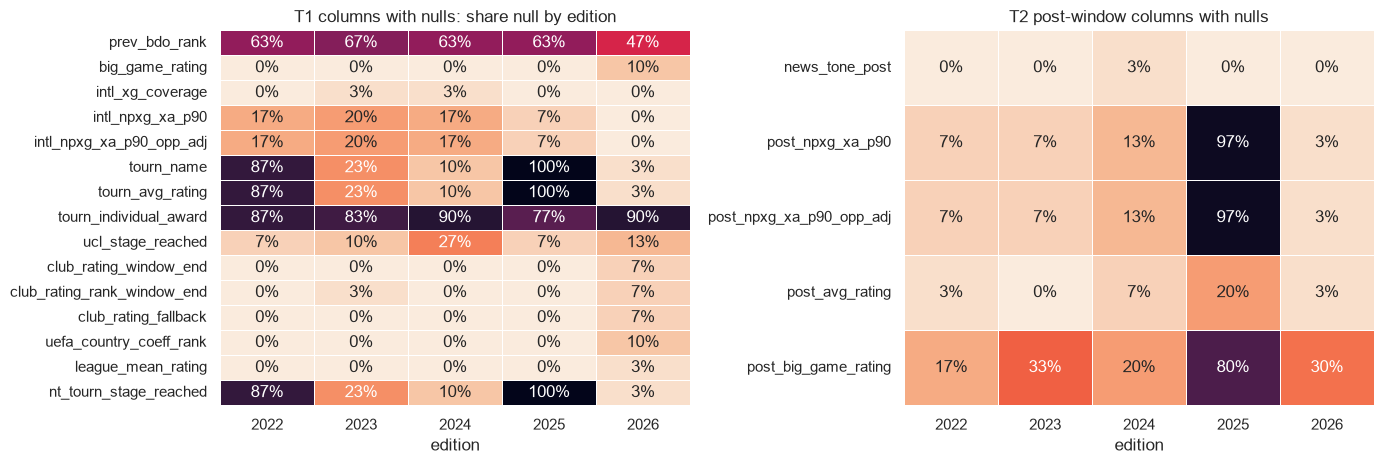

Targets (bdo_points / bdo_rank / vote_share) are null for 2026 only: the forecast edition.


In [16]:
def null_share_by_edition(df: pd.DataFrame) -> pd.DataFrame:
    shares = df.drop(columns=["edition"]).isna().groupby(df["edition"]).mean().T
    return shares.loc[shares.sum(axis=1) > 0]

miss_t1 = null_share_by_edition(t1.drop(columns=TARGET_COLS))
miss_post = null_share_by_edition(t2[["edition"] + extra])

fig, axes = plt.subplots(1, 2, figsize=(14, max(4, 0.32 * max(len(miss_t1), len(miss_post)))), gridspec_kw={"width_ratios": [1, 1]})
sns.heatmap(miss_t1, annot=True, fmt=".0%", cmap="rocket_r", vmin=0, vmax=1, cbar=False, ax=axes[0], linewidths=0.5)
axes[0].set_title("T1 columns with nulls: share null by edition")
sns.heatmap(miss_post, annot=True, fmt=".0%", cmap="rocket_r", vmin=0, vmax=1, cbar=False, ax=axes[1], linewidths=0.5)
axes[1].set_title("T2 post-window columns with nulls")
for ax in axes:
    ax.set_xlabel("edition")
plt.tight_layout()
plt.savefig("figures/eda/b_missingness_by_edition.png", dpi=150)
plt.show()
print("Targets (bdo_points / bdo_rank / vote_share) are null for 2026 only: the forecast edition.")

In [17]:
# Which nulls are 'structural' (did not play) vs 'unexplained'? Totals per column, all editions.
tot = t2.isna().sum()
tot = tot[tot > 0].sort_values(ascending=False).to_frame("null_rows")
tot["null_%"] = (tot["null_rows"] / len(t2) * 100).round(1)
display(tot)

,null_rows,null_%
tourn_individual_award,128,85.3
prev_bdo_rank,91,60.7
tourn_avg_rating,67,44.7
nt_tourn_stage_reached,67,44.7
tourn_name,67,44.7
post_big_game_rating,54,36.0
post_npxg_xa_p90_opp_adj,38,25.3
post_npxg_xa_p90,38,25.3
bdo_rank,30,20.0
bdo_points,30,20.0


### B4. Target anatomy — how the points are distributed

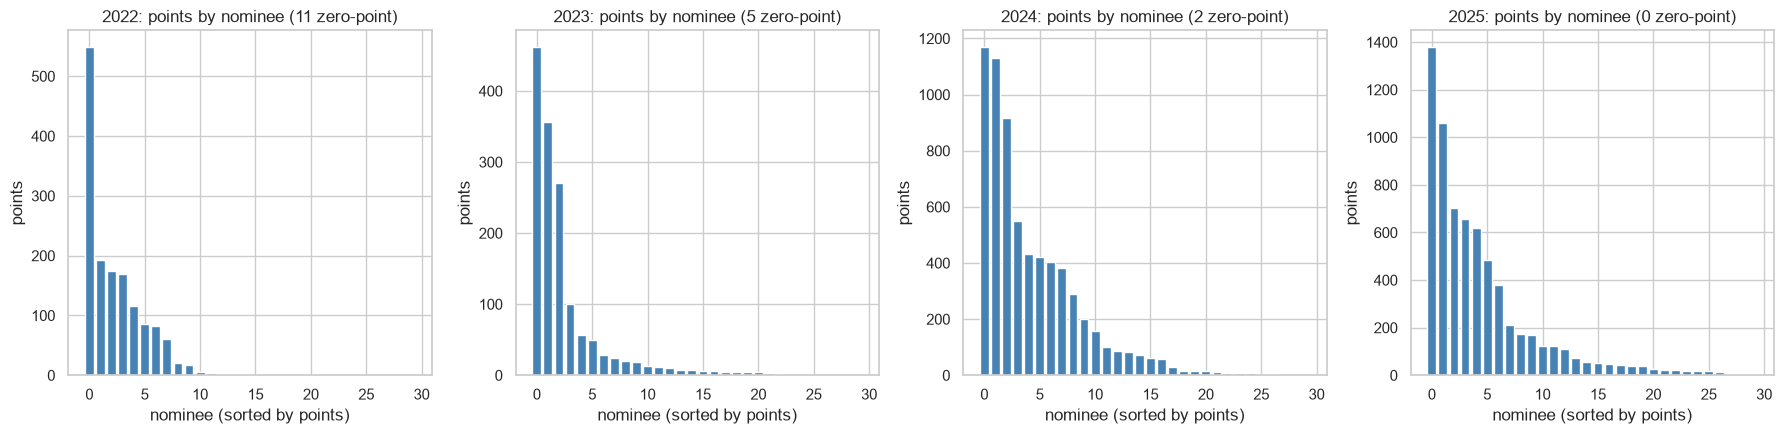

,points_total,n_voted,n_zero_points,winner_points,winner_share,top3_share,herfindahl,winner
edition,,,,,,,,
2022,1488.0,19,11,549.0,0.368952,0.616263,0.194243,Karim Benzema
2023,1472.0,25,5,462.0,0.313859,0.739810,0.199489,Lionel Messi
2024,6633.0,28,2,1170.0,0.176391,0.484848,0.105609,Rodri
2025,6700.0,30,0,1380.0,0.205970,0.468955,0.108736,Ousmane Dembélé


In [18]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=False)
for ax, (ed, g) in zip(axes, train.groupby("edition")):
    g = g.sort_values(["bdo_points", "player_name"], ascending=[False, True]).reset_index(drop=True)
    colors = np.where(g["bdo_points"] == 0, "lightgrey", "steelblue")
    ax.bar(range(len(g)), g["bdo_points"], color=colors)
    ax.set_title(f"{ed}: points by nominee ({(g['bdo_points'] == 0).sum()} zero-point)")
    ax.set_xlabel("nominee (sorted by points)")
    ax.set_ylabel("points")
plt.tight_layout()
plt.savefig("figures/eda/b_points_by_edition.png", dpi=150)
plt.show()

conc = train.groupby("edition").apply(lambda g: pd.Series({
    "points_total": g["bdo_points"].sum(),
    "n_voted": int((g["bdo_points"] > 0).sum()),
    "n_zero_points": int((g["bdo_points"] == 0).sum()),
    "winner_points": g["bdo_points"].max(),
    "winner_share": g["bdo_points"].max() / g["bdo_points"].sum(),
    "top3_share": g["bdo_points"].nlargest(3).sum() / g["bdo_points"].sum(),
    "herfindahl": ((g["bdo_points"] / g["bdo_points"].sum()) ** 2).sum(),
    "winner": g.loc[g["bdo_points"].idxmax(), "player_name"],
}), include_groups=False)
display(conc)

In [19]:
# vote_share consistency and rank vs points
share_gap = (train["vote_share"] - train["bdo_points"] / train.groupby("edition")["bdo_points"].transform("sum")).abs().max()
print(f"max |vote_share - points/total| = {share_gap:.2e}")

print("Tied point totals among VOTED players (these need Breslow handling later):")
display(tied_voted.sort_values(["edition", "bdo_points"], ascending=[True, False])[["edition", "player_name", "bdo_points", "bdo_rank"]])

print("Zero-point nominees and their bdo_rank (rank is shared/tied -> points, not rank, must define the order):")
display(train[train["bdo_points"] == 0].groupby("edition")["bdo_rank"].apply(lambda s: sorted(s.tolist())).to_frame("zero_point_ranks"))
print("bdo_rank unique per edition:", train.groupby("edition")["bdo_rank"].apply(lambda s: s.is_unique).to_dict())

max |vote_share - points/total| = 9.63e-17
Tied point totals among VOTED players (these need Breslow handling later):


,edition,player_name,bdo_points,bdo_rank
16,2022,Rafael Leão,2.0,14.0
24,2022,Fabinho,2.0,14.0
26,2022,Sébastien Haller,2.0,13.0
1,2022,Virgil van Dijk,1.0,16.0
11,2022,Dušan Vlahović,1.0,17.0
13,2022,Luis Díaz,1.0,17.0
22,2022,Casemiro,1.0,17.0
36,2023,Karim Benzema,6.0,16.0
55,2023,Khvicha Kvaratskhelia,6.0,17.0
39,2023,Lautaro Martínez,4.0,20.0


Zero-point nominees and their bdo_rank (rank is shared/tied -> points, not rank, must define the order):


,zero_point_ranks
edition,
2022,"[20.0, 21.0, 22.0, 22.0, 22.0, 25.0, 25.0, 25...."
2023,"[26.0, 27.0, 28.0, 28.0, 30.0]"
2024,"[29.0, 29.0]"


bdo_rank unique per edition: {2022: False, 2023: False, 2024: False, 2025: True}


### B5. Who the nominees are — positions and the 2026 forecast pool

position_group,DEF,FWD,GK,MID
edition,,,,
2022,4,15,2,9
2023,3,15,3,9
2024,6,11,1,12
2025,4,15,1,10
2026,9,14,0,7


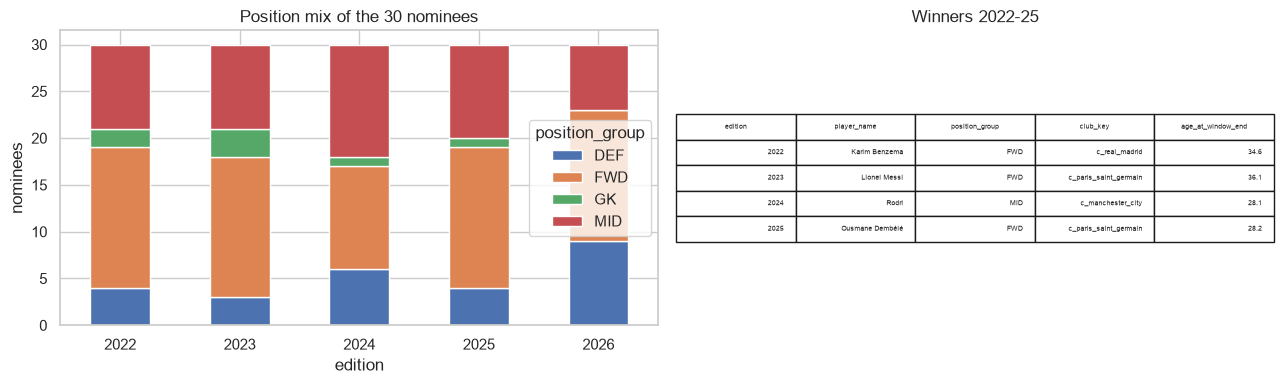

In [20]:
pos = pd.crosstab(t1["edition"], t1["position_group"])
display(pos)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
pos.plot.bar(stacked=True, ax=ax[0], rot=0)
ax[0].set_title("Position mix of the 30 nominees")
ax[0].set_ylabel("nominees")
winners = train.loc[train.groupby("edition")["bdo_points"].idxmax(), ["edition", "player_name", "position_group", "club_key", "age_at_window_end"]]
ax[1].axis("off")
ax[1].table(cellText=winners.values, colLabels=winners.columns, loc="center").scale(1, 1.6)
ax[1].set_title("Winners 2022-25")
plt.tight_layout()
plt.savefig("figures/eda/b_positions_and_winners.png", dpi=150)
plt.show()